# Análisis Exploratorio y Visualización de Datos — Consumo de Combustible de Automóviles

El dataset **mpg** contiene 398 automóviles de los años 1970 a 1982 con su consumo de combustible y características técnicas.

**Variables:** `mpg` (millas por galón, a mayor valor menor consumo), `cylinders`, `displacement` (cilindrada), `horsepower` (potencia), `weight` (peso en libras), `acceleration`, `model_year`, `origin` (usa, europe, japan) y `name`.

**Objetivo:** explorar la calidad de los datos, describir cada variable y estudiar qué factores determinan la eficiencia de los autos, con visualizaciones **nuevas** (en clase se vieron gráficos de líneas y de barras): histograma con KDE, diagrama de cajas y bigotes, dispersión con recta de regresión, mapa de calor de correlación y gráfico de violín.

## 1. Librerías y carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Dataset 'mpg' (seaborn), guardado como CSV
data = pd.read_csv('autos.csv')
data.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## 2. Estructura y calidad de los datos

In [2]:
# Tipos de datos, valores no nulos y memoria
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [4]:
# Valores faltantes y registros duplicados
print('Valores nulos por columna:')
print(data.isna().sum())
print(f'\nRegistros duplicados: {data.duplicated().sum()}')

# Autos con potencia desconocida
data[data['horsepower'].isna()]

Valores nulos por columna:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Registros duplicados: 0


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25.0,4,98.0,NaN,2046,19.0,71,usa,ford pinto
126,21.0,6,200.0,NaN,2875,17.0,74,usa,ford maverick
330,40.9,4,85.0,NaN,1835,17.3,80,europe,renault lecar deluxe
336,23.6,4,140.0,NaN,2905,14.3,80,usa,ford mustang cobra
354,34.5,4,100.0,NaN,2320,15.8,81,europe,renault 18i
374,23.0,4,151.0,NaN,3035,20.5,82,usa,amc concord dl


In [5]:
# Distribución de las variables categóricas
for col in ['origin', 'cylinders']:
    print(data[col].value_counts().sort_index(), '\n')

origin
europe     70
japan      79
usa       249
Name: count, dtype: int64 

cylinders
3      4
4    204
5      3
6     84
8    103
Name: count, dtype: int64 



In [6]:
# Número de valores únicos por columna
data.nunique()

mpg             129
cylinders         5
displacement     82
horsepower       93
weight          351
acceleration     95
model_year       13
origin            3
name            305
dtype: int64

**Hallazgos de calidad:** hay 398 registros y ningún duplicado. El único campo con faltantes es `horsepower`, con 6 nulos (1.5 %). El 62.6 % de los autos es de origen estadounidense (249 de 398), y la mayoría tiene 4 cilindros (204), 8 cilindros (103) o 6 cilindros (84); los de 3 y 5 cilindros son muy pocos (4 y 3).

## 3. Estadística descriptiva

In [7]:
data.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [9]:
num_cols = ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']
num = data[num_cols]

resumen = pd.DataFrame({
    'media': num.mean(),
    'mediana': num.median(),
    'moda': num.mode().iloc[0],
    'desv_std': num.std(),
    'varianza': num.var(),
    'rango': num.max() - num.min(),
    'IQR': num.quantile(0.75) - num.quantile(0.25),
    'coef_variacion_%': num.std() / num.mean() * 100,
    'asimetria': num.skew(),
    'curtosis': num.kurt()
})
resumen

,media,mediana,moda,desv_std,varianza,rango,IQR,coef_variacion_%,asimetria,curtosis
mpg,23.514573,23.0,13.0,7.815984,61.089611,37.6,11.50,33.238896,0.457066,-0.510781
displacement,193.425879,148.5,97.0,104.269838,10872.199152,387.0,157.75,53.906870,0.719645,-0.746597
horsepower,104.469388,93.5,150.0,38.491160,1481.569393,184.0,51.00,36.844439,1.087326,0.696947
weight,2970.424623,2803.5,1985.0,846.841774,717140.990526,3527.0,1384.25,28.509115,0.531063,-0.785529
acceleration,15.568090,15.5,14.5,2.757689,7.604848,16.8,3.35,17.713726,0.278777,0.419497


## 4. Limpieza

In [10]:
df = data.dropna().copy()
print('Filas antes:', len(data), '| Filas después:', len(df))
print('Nulos restantes:', df.isna().sum().sum())

Filas antes: 398 | Filas después: 392
Nulos restantes: 0


## 5. Estadísticas por origen

In [11]:
df.groupby('origin')[['mpg', 'weight', 'horsepower']].agg(['mean', 'median', 'std']).round(1)

mpg              weight                horsepower             
        mean median  std    mean  median    std       mean median   std
origin                                                                 
europe  27.6   26.0  6.6  2433.5  2240.0  491.8       80.6   76.5  20.2
japan   30.5   31.6  6.1  2221.2  2155.0  320.5       79.8   75.0  17.8
usa     20.0   18.5  6.4  3372.5  3381.0  795.3      119.0  105.0  39.9

## 6. Visualizaciones nuevas

### 6.1 Histograma con curva KDE — consumo (mpg) por origen

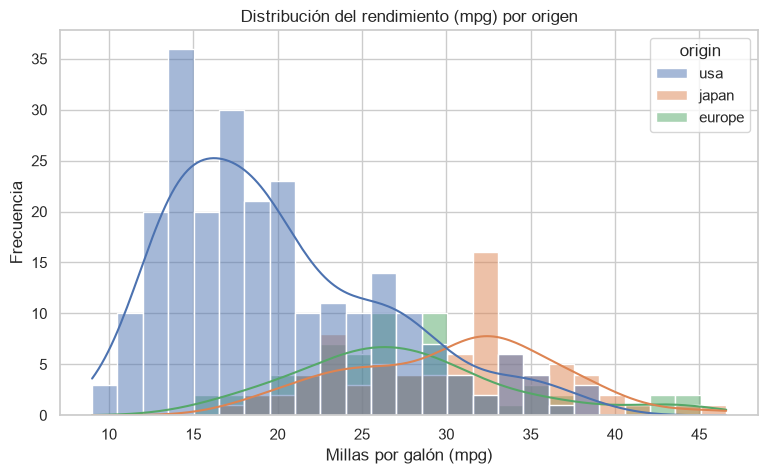

In [12]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='mpg', hue='origin', kde=True, bins=25, alpha=0.5)
plt.title('Distribución del rendimiento (mpg) por origen')
plt.xlabel('Millas por galón (mpg)')
plt.ylabel('Frecuencia')
plt.show()

**Interpretación:** la distribución global de `mpg` tiene asimetría positiva (0.46), con la mayoría de autos entre 15 y 30 mpg y una cola hacia valores altos. Por origen, los autos japoneses (media 30.5 mpg) y europeos (27.6 mpg) se concentran en rendimientos altos, mientras que los estadounidenses (media 20.0 mpg) se concentran en valores bajos.

**Conclusión:** en esta época los autos de EE. UU. consumían notablemente más combustible que los importados.

### 6.2 Diagrama de cajas y bigotes (boxplot) — mpg por origen y por cilindros

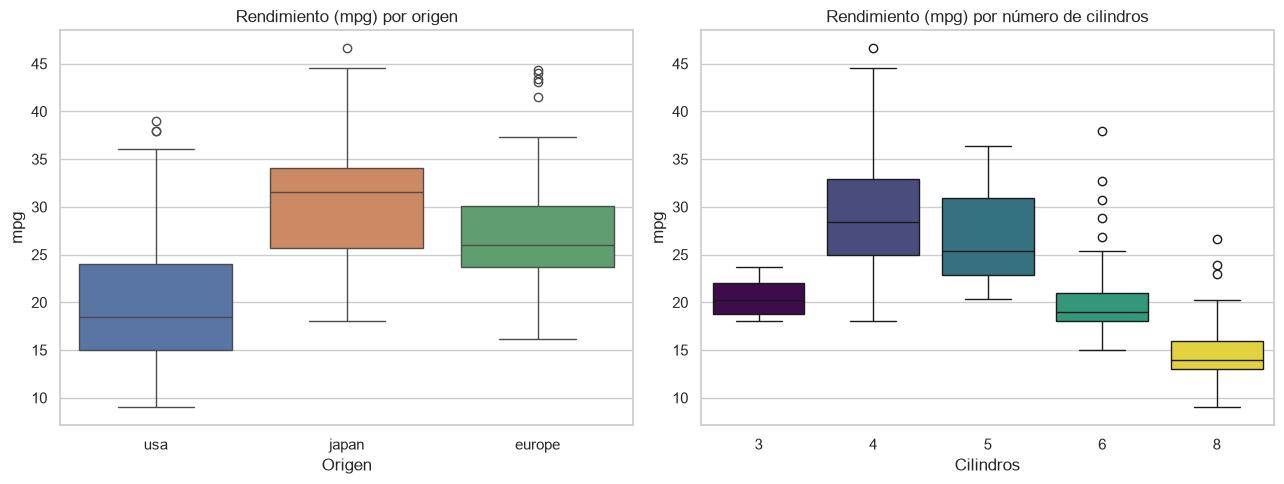

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x='origin', y='mpg', hue='origin', ax=axes[0])
axes[0].set_title('Rendimiento (mpg) por origen')
axes[0].set_xlabel('Origen')
axes[0].set_ylabel('mpg')

sns.boxplot(data=df, x='cylinders', y='mpg', hue='cylinders', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Rendimiento (mpg) por número de cilindros')
axes[1].set_xlabel('Cilindros')
axes[1].set_ylabel('mpg')

plt.tight_layout()
plt.show()

**Interpretación:** por origen, la mediana de los autos japoneses (31.6 mpg) supera a la de los europeos (26.0) y a la de los estadounidenses (18.5). Estos últimos tienen la mayor dispersión (IQR de 9.0 frente a 8.3 de Japón y 6.4 de Europa). Hay valores atípicos en los tres orígenes (5 en Europa, 1 en Japón y 3 en EE. UU.), siempre hacia rendimientos altos.

Por cilindros, la mediana baja al aumentar los cilindros: 28.4 mpg con 4 cilindros, 19.0 con 6 y 14.0 con 8. La categoría de 6 cilindros presenta 5 valores atípicos. Las categorías de 3 y 5 cilindros tienen muy pocos autos (4 y 3), por lo que sus cajas no son representativas.

**Conclusión:** el número de cilindros y el origen explican bien el rendimiento. Los valores atípicos son autos eficientes plausibles y se conservaron.

### 6.3 Diagrama de dispersión con recta de regresión — peso vs. mpg

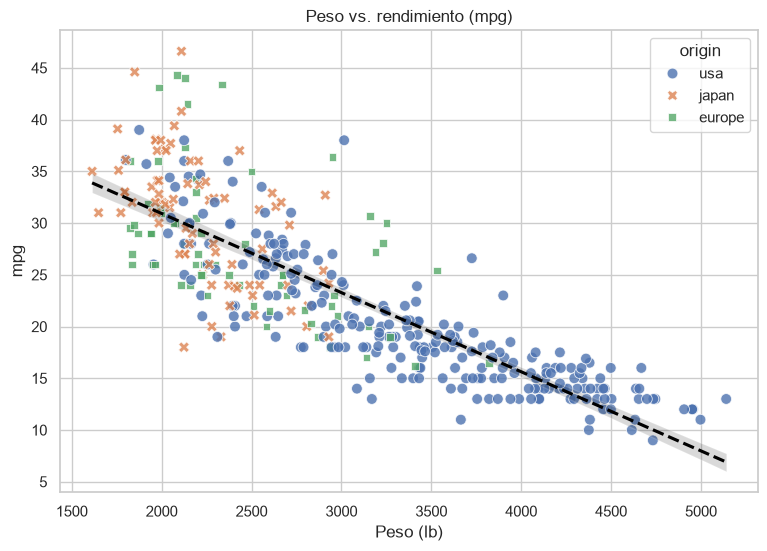

Correlación global: -0.83
origin
europe   -0.51
japan    -0.56
usa      -0.85
dtype: float64


In [14]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='weight', y='mpg', hue='origin', style='origin', s=60, alpha=0.8)
sns.regplot(data=df, x='weight', y='mpg', scatter=False, color='black', line_kws={'linestyle': '--'})
plt.title('Peso vs. rendimiento (mpg)')
plt.xlabel('Peso (lb)')
plt.ylabel('mpg')
plt.show()

print('Correlación global:', round(df['weight'].corr(df['mpg']), 2))
print(df.groupby('origin').apply(lambda g: round(g['weight'].corr(g['mpg']), 2), include_groups=False))

**Interpretación:** existe una relación negativa fuerte entre el peso y el rendimiento (r = -0.83): los autos más pesados recorren menos millas por galón. Dentro de cada origen la relación se mantiene negativa, pero con distinta intensidad: -0.85 en EE. UU., -0.56 en Japón y -0.51 en Europa. Los autos estadounidenses se ubican a la derecha (más pesados) y abajo (menos eficientes), y los japoneses y europeos en la zona liviana y eficiente.

**Conclusión:** el peso es uno de los mejores predictores del consumo. Reducir el peso mejora el rendimiento.

### 6.4 Mapa de calor de correlaciones

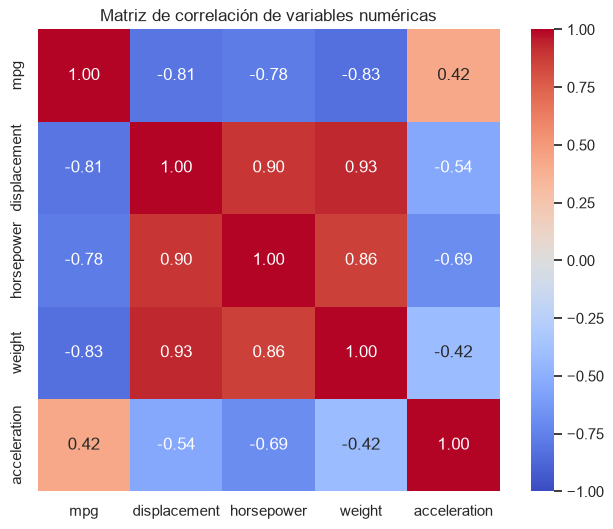

In [15]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', square=True)
plt.title('Matriz de correlación de variables numéricas')
plt.show()

**Interpretación:** `mpg` se correlaciona negativamente con el peso (-0.83), la cilindrada (-0.81) y la potencia (-0.78): más tamaño y potencia implican más consumo. Las variables técnicas están muy relacionadas entre sí: cilindrada-peso (0.93), cilindrada-potencia (0.90) y potencia-peso (0.86), lo que indica **multicolinealidad**. La aceleración (segundos de 0 a 60 mph) tiene una correlación débil con `mpg` (0.42) y negativa con la potencia (-0.69), porque más potencia significa menos tiempo de aceleración.

**Conclusión:** peso, cilindrada y potencia miden en parte lo mismo, por lo que en un modelo predictivo no conviene usarlas todas a la vez.

### 6.5 Gráfico de violín — peso por origen

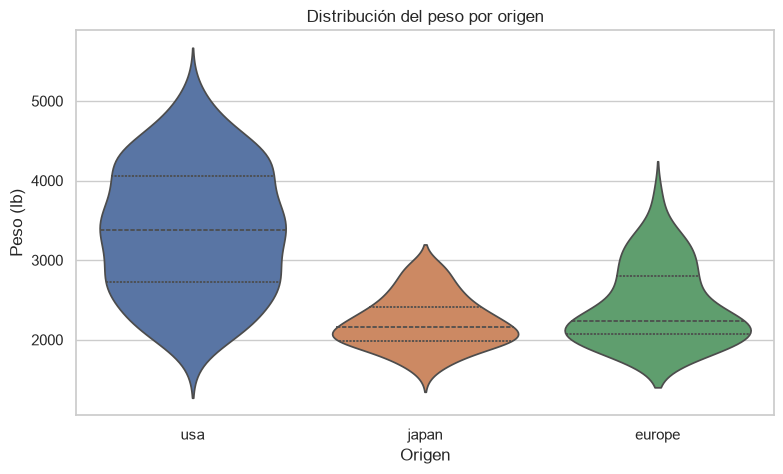

,mean,std,min,max
origin,,,,
europe,2433.0,492.0,1825,3820
japan,2221.0,320.0,1613,2930
usa,3372.0,795.0,1800,5140


In [16]:
plt.figure(figsize=(9, 5))
sns.violinplot(data=df, x='origin', y='weight', hue='origin', inner='quart')
plt.title('Distribución del peso por origen')
plt.xlabel('Origen')
plt.ylabel('Peso (lb)')
plt.show()

df.groupby('origin')['weight'].agg(['mean', 'std', 'min', 'max']).round(0)

**Interpretación:** los autos estadounidenses pesan en promedio 3372 lb, frente a 2433 lb de los europeos y 2221 lb de los japoneses. Además, la distribución de EE. UU. es mucho más amplia (desviación estándar de 795 lb, contra 492 lb en Europa y 320 lb en Japón) y va de 1800 a 5140 lb, es decir, producían desde autos compactos hasta vehículos muy pesados. Los importados se concentran en un rango estrecho de autos livianos.

**Conclusión:** la diferencia de peso entre orígenes ayuda a explicar la diferencia de rendimiento observada en los gráficos anteriores.

## 7. Conclusiones generales

- **Calidad de datos:** dataset limpio, sin duplicados y con solo 6 nulos (1.5 %) en `horsepower`, eliminados para el análisis.
- **Origen:** los autos japoneses (30.5 mpg de media) y europeos (27.6) son más eficientes que los estadounidenses (20.0).
- **Factores técnicos:** el rendimiento cae al aumentar el peso (r = -0.83), la cilindrada (-0.81) y la potencia (-0.78).
- **Cilindros:** la mediana baja de 28.4 mpg (4 cilindros) a 19.0 (6) y 14.0 (8).
- **Multicolinealidad:** peso, cilindrada y potencia están fuertemente correlacionados entre sí (0.86 a 0.93).
- **Explicación del origen:** los autos de EE. UU. son más pesados y potentes en promedio (3372 lb y 119 hp frente a unas 2200-2400 lb y 80-81 hp de los importados).
- **Atípicos:** son pocos, corresponden a autos muy eficientes y se conservaron.